In [ ]:
import pandas as pd
import numpy as np
from lightgbm import LGBMRegressor, early_stopping
import optuna
import sys
from pathlib import Path
import warnings
import torch

DIR_ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(DIR_ROOT))

warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2

/home/koyo-ai/miniconda3/envs/homeless/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
SEED = 987
TRACK = "off_market"                     # "off_market" or "list_aware"
VAL_START = pd.Timestamp("2025-12-01")    # sales on or after this date are validation
N_TRIALS = 10                             # optuna trials
N_ESTIMATORS = 2000                      # max boosting rounds per trial
EARLY_STOPPING_ROUNDS = 100
ES_FRACTION = 0.1                         # latest share of each fold's training rows used for early stopping
K_FOLDS = 5                              # time series cross validation folds
DEBUG = True                             # print MdAPE and MAPE for every fold
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # Use GPU if available, otherwise CPU

In [3]:
import data

listings = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")

In [4]:
from xxbonkxx_features import off_market_features, list_aware_features

make_features = off_market_features if TRACK == "off_market" else list_aware_features

train = listings[listings["date_sold"] < VAL_START]
val = listings[listings["date_sold"] >= VAL_START]

X_train = make_features(train)
X_val = make_features(val)

y_train = np.log(train["sold_price"])
y_val = np.log(val["sold_price"])
# y_train = train["sold_price"]
# y_val = val["sold_price"]

print(f"Features: {X_train.columns.tolist()}")
print(f"train: {len(train):,} sales up to {VAL_START.date()}")
print(f"val:   {len(val):,} sales from {VAL_START.date()}")

Features: ['house_area_was_range', 'square_feet', 'bedrooms', 'washrooms', 'parking', 'lot_front', 'lot_depth', 'lot_missing', 'latitude', 'longitude', 'municipality', 'community', 'house_type', 'house_style', 'is_apartment', 'month', 'year', 'day', 'lag_annual', 'lag_semi_annual']
train: 139,931 sales up to 2025-12-01
val:   10,069 sales from 2025-12-01


In [5]:
def mdape_log(y_log, pred_log):
    return 100 * np.median(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

def mape_log(y_log, pred_log):
    return 100 * np.mean(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

def mdape(y, pred):
    return 100 * np.median(np.abs(pred - y) / np.abs(y))

def mape(y, pred):
    return 100 * np.mean(np.abs(pred - y) / np.abs(y))

target_space = "log"

In [ ]:
from sklearn.model_selection import TimeSeriesSplit


def cross_val(X, y, params, K=5, debug=False, target_space="log"):
    """Walk-forward K-fold: each fold trains on every row before its validation block.
    X and y must be sorted by time (listings is sorted by date_sold).
    Early stopping uses the latest ES_FRACTION of each fold's training rows, never the
    validation block, so the fold scores are honest.
    Returns (mean validation loss, mean boosting rounds used) over the folds."""
    mdape_scores = []
    mape_scores = []
    rounds = []
    for fold, (train_idx, val_idx) in enumerate(TimeSeriesSplit(n_splits=K).split(X), start=1):
        n_fit = int(len(train_idx) * (1 - ES_FRACTION))
        fit_idx, es_idx = train_idx[:n_fit], train_idx[n_fit:]
        X_fit, X_es, X_va = X.iloc[fit_idx], X.iloc[es_idx], X.iloc[val_idx]
        y_fit, y_es, y_va = y.iloc[fit_idx], y.iloc[es_idx], y.iloc[val_idx]

        model = LGBMRegressor(**params, n_estimators=N_ESTIMATORS, random_state=SEED, verbosity=-1, device=DEVICE)
        model.fit(X_fit, y_fit, eval_set=[(X_es, y_es)],
                  callbacks=[early_stopping(EARLY_STOPPING_ROUNDS, verbose=False)])
        rounds.append(model.best_iteration_)
        pred = model.predict(X_va)
        if target_space == "log":
            mdape_scores.append(mdape_log(y_va, pred))
        else:
            mdape_scores.append(mdape(y_va, pred))

        if target_space == "log":
            mape_scores.append(mape_log(y_va, pred))
        else:
            mape_scores.append(mape(y_va, pred))

        if debug:
            mdape_error = mdape_scores[-1]
            mape_error = mape_scores[-1]
            print(f"fold {fold}: train {len(fit_idx):,}  early stop {len(es_idx):,}  val {len(val_idx):,}  "
                  f"rounds {rounds[-1]}  MdAPE {mdape_error:.2f}%  MAPE {mape_error:.2f}%", flush=True)

    print(f"mean MdAPE {np.mean(mdape_scores):.2f}%  mean MAPE {np.mean(mape_scores):.2f}%", flush=True)
    return np.mean(mdape_scores), int(np.mean(rounds))

In [7]:
def objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, step=0.01),
        "num_leaves": trial.suggest_int("num_leaves", 15, 255),
        "max_depth": trial.suggest_int("max_depth", 3, 13),
        "subsample": trial.suggest_float("subsample", 0.1, 1.0, step=0.1),
        "subsample_freq": 1,  # LightGBM ignores subsample unless bagging runs every k rounds
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.1, 1.0, step=0.1),
        "max_bin": trial.suggest_int("max_bin", 256, 2048),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
        "min_split_gain": trial.suggest_float("min_split_gain", 0, 0.1, step=0.01),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
    }
    score, n_rounds = cross_val(X_train, y_train, params, K=K_FOLDS, debug=DEBUG, target_space=target_space)
    trial.set_user_attr("n_rounds", n_rounds)
    return score

In [9]:
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED), study_name="VAPE GOD VAPE GOD VAPE GOD 420 420 696969!!!!")
study.optimize(objective, n_trials=N_TRIALS)

print("best CV MdAPE:", round(study.best_value, 2))
print("best params:", study.best_params)
print("boosting rounds:", study.best_trial.user_attrs["n_rounds"])

[I 2026-10-17 20:29:45,050] A new study created in memory with name: VAPE GOD VAPE GOD VAPE GOD 420 420 696969!!!!


fold 1: train 20,993  early stop 2,333  val 23,321  rounds 768  MdAPE 11.16%  MAPE 13.51%
fold 2: train 41,982  early stop 4,665  val 23,321  rounds 885  MdAPE 11.38%  MAPE 14.01%
fold 3: train 62,971  early stop 6,997  val 23,321  rounds 858  MdAPE 10.26%  MAPE 12.77%
fold 4: train 83,960  early stop 9,329  val 23,321  rounds 1256  MdAPE 10.28%  MAPE 13.24%
fold 5: train 104,949  early stop 11,661  val 23,321  rounds 905  MdAPE 11.44%  MAPE 14.54%
mean MdAPE 10.91%  mean MAPE 13.61%


[I 2026-10-17 20:30:12,682] Trial 0 finished with value: 10.90554067012849 and parameters: {'learning_rate': 0.05, 'num_leaves': 109, 'max_depth': 12, 'subsample': 0.5, 'colsample_bytree': 0.9, 'max_bin': 1904, 'min_child_samples': 92, 'min_split_gain': 0.1, 'reg_lambda': 0.0013187949354214168, 'reg_alpha': 0.002296326109404726}. Best is trial 0 with value: 10.90554067012849.


fold 1: train 20,993  early stop 2,333  val 23,321  rounds 602  MdAPE 11.32%  MAPE 13.60%
fold 2: train 41,982  early stop 4,665  val 23,321  rounds 311  MdAPE 11.74%  MAPE 14.32%
fold 3: train 62,971  early stop 6,997  val 23,321  rounds 905  MdAPE 10.38%  MAPE 12.97%
fold 4: train 83,960  early stop 9,329  val 23,321  rounds 1991  MdAPE 10.66%  MAPE 13.68%
fold 5: train 104,949  early stop 11,661  val 23,321  rounds 768  MdAPE 11.99%  MAPE 15.25%
mean MdAPE 11.22%  mean MAPE 13.96%


[I 2026-10-17 20:30:26,529] Trial 1 finished with value: 11.218857609087276 and parameters: {'learning_rate': 0.09, 'num_leaves': 31, 'max_depth': 11, 'subsample': 0.8, 'colsample_bytree': 0.4, 'max_bin': 712, 'min_child_samples': 78, 'min_split_gain': 0.1, 'reg_lambda': 0.0058203973119644765, 'reg_alpha': 1.6737942711873728}. Best is trial 0 with value: 10.90554067012849.


...

fold 1: train 20,993  early stop 2,333  val 23,321  rounds 1999  MdAPE 11.72%  MAPE 13.96%
fold 2: train 41,982  early stop 4,665  val 23,321  rounds 1982  MdAPE 11.98%  MAPE 14.59%
fold 3: train 62,971  early stop 6,997  val 23,321  rounds 2000  MdAPE 10.76%  MAPE 13.42%
fold 4: train 83,960  early stop 9,329  val 23,321  rounds 2000  MdAPE 11.38%  MAPE 14.40%
fold 5: train 104,949  early stop 11,661  val 23,321  rounds 2000  MdAPE 12.88%  MAPE 16.29%
mean MdAPE 11.74%  mean MAPE 14.53%


[I 2026-10-17 20:33:21,218] Trial 8 finished with value: 11.744484374641138 and parameters: {'learning_rate': 0.02, 'num_leaves': 119, 'max_depth': 6, 'subsample': 0.8, 'colsample_bytree': 0.1, 'max_bin': 259, 'min_child_samples': 18, 'min_split_gain': 0.1, 'reg_lambda': 0.030559905399179667, 'reg_alpha': 0.9165462751971704}. Best is trial 2 with value: 10.386190673959456.


fold 1: train 20,993  early stop 2,333  val 23,321  rounds 402  MdAPE 11.14%  MAPE 13.49%
fold 2: train 41,982  early stop 4,665  val 23,321  rounds 326  MdAPE 11.45%  MAPE 14.10%
fold 3: train 62,971  early stop 6,997  val 23,321  rounds 460  MdAPE 10.12%  MAPE 12.66%
fold 4: train 83,960  early stop 9,329  val 23,321  rounds 455  MdAPE 10.41%  MAPE 13.31%
fold 5: train 104,949  early stop 11,661  val 23,321  rounds 727  MdAPE 11.07%  MAPE 14.19%
mean MdAPE 10.84%  mean MAPE 13.55%


[I 2026-10-17 20:33:33,289] Trial 9 finished with value: 10.836609938146413 and parameters: {'learning_rate': 0.09999999999999999, 'num_leaves': 124, 'max_depth': 13, 'subsample': 0.6, 'colsample_bytree': 0.6, 'max_bin': 926, 'min_child_samples': 86, 'min_split_gain': 0.09, 'reg_lambda': 0.11463214978336936, 'reg_alpha': 0.14324348812516427}. Best is trial 2 with value: 10.386190673959456.


best CV MdAPE: 10.39
best params: {'learning_rate': 0.05, 'num_leaves': 199, 'max_depth': 9, 'subsample': 0.7000000000000001, 'colsample_bytree': 1.0, 'max_bin': 1704, 'min_child_samples': 33, 'min_split_gain': 0.03, 'reg_lambda': 4.998638172864346, 'reg_alpha': 0.08875820641896254}
boosting rounds: 866


In [10]:
from optuna.importance import get_param_importances

importance = get_param_importances(study)

for param, score in importance.items():
    print(f"{param}: {score:.4f}")

reg_lambda: 0.2907
num_leaves: 0.2026
min_child_samples: 0.1408
reg_alpha: 0.1303
max_bin: 0.1123
min_split_gain: 0.0356
colsample_bytree: 0.0253
learning_rate: 0.0243
max_depth: 0.0224
subsample: 0.0158


In [11]:
# The validation set is only scored, never used for fitting or early stopping:
# the number of rounds comes from cross validation on the training sales.
model = LGBMRegressor(**study.best_params,
                      subsample_freq=1,
                      importance_type="gain",
                      n_estimators=study.best_trial.user_attrs["n_rounds"],
                      random_state=SEED,
                      verbosity=-1)
model.fit(X_train, y_train)

predicted = np.exp(model.predict(X_val))
error = 100 * np.abs(predicted / val["sold_price"] - 1)
print(f"{TRACK}  MdAPE {error.median():.2f}%  MAPE {error.mean():.2f}%")

off_market  MdAPE 9.26%  MAPE 11.85%


In [12]:
feature_importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
display(feature_importances)

lot_front               110357.752143
square_feet              54034.134123
community                48204.686169
washrooms                17585.987497
lot_missing               9329.349854
lot_depth                 7181.973122
latitude                  4332.806814
longitude                 3602.487339
day                       3546.114666
house_type                2439.418775
parking                   1237.696891
lag_semi_annual           1073.091436
lag_annual                 983.019412
month                      758.805048
house_style                400.909314
bedrooms                    93.903261
house_area_was_range        44.245523
year                        17.771121
is_apartment                17.083345
municipality                 2.290300
dtype: float64

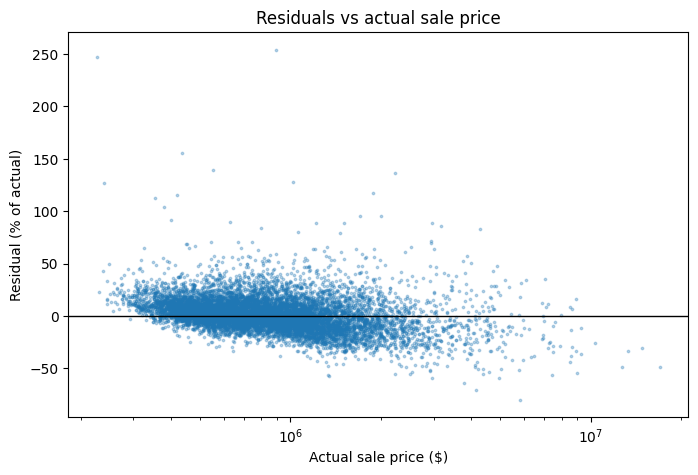

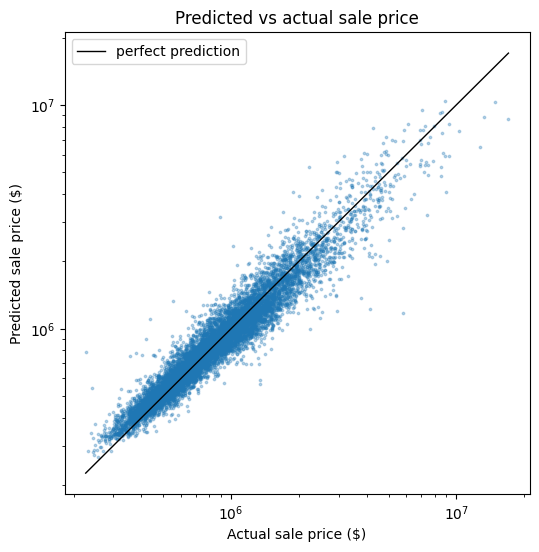

In [13]:
import diagnostics

actual = val["sold_price"]

diagnostics.plot_residuals_vs_actual(actual, predicted)
diagnostics.plot_predicted_vs_actual(actual, predicted)

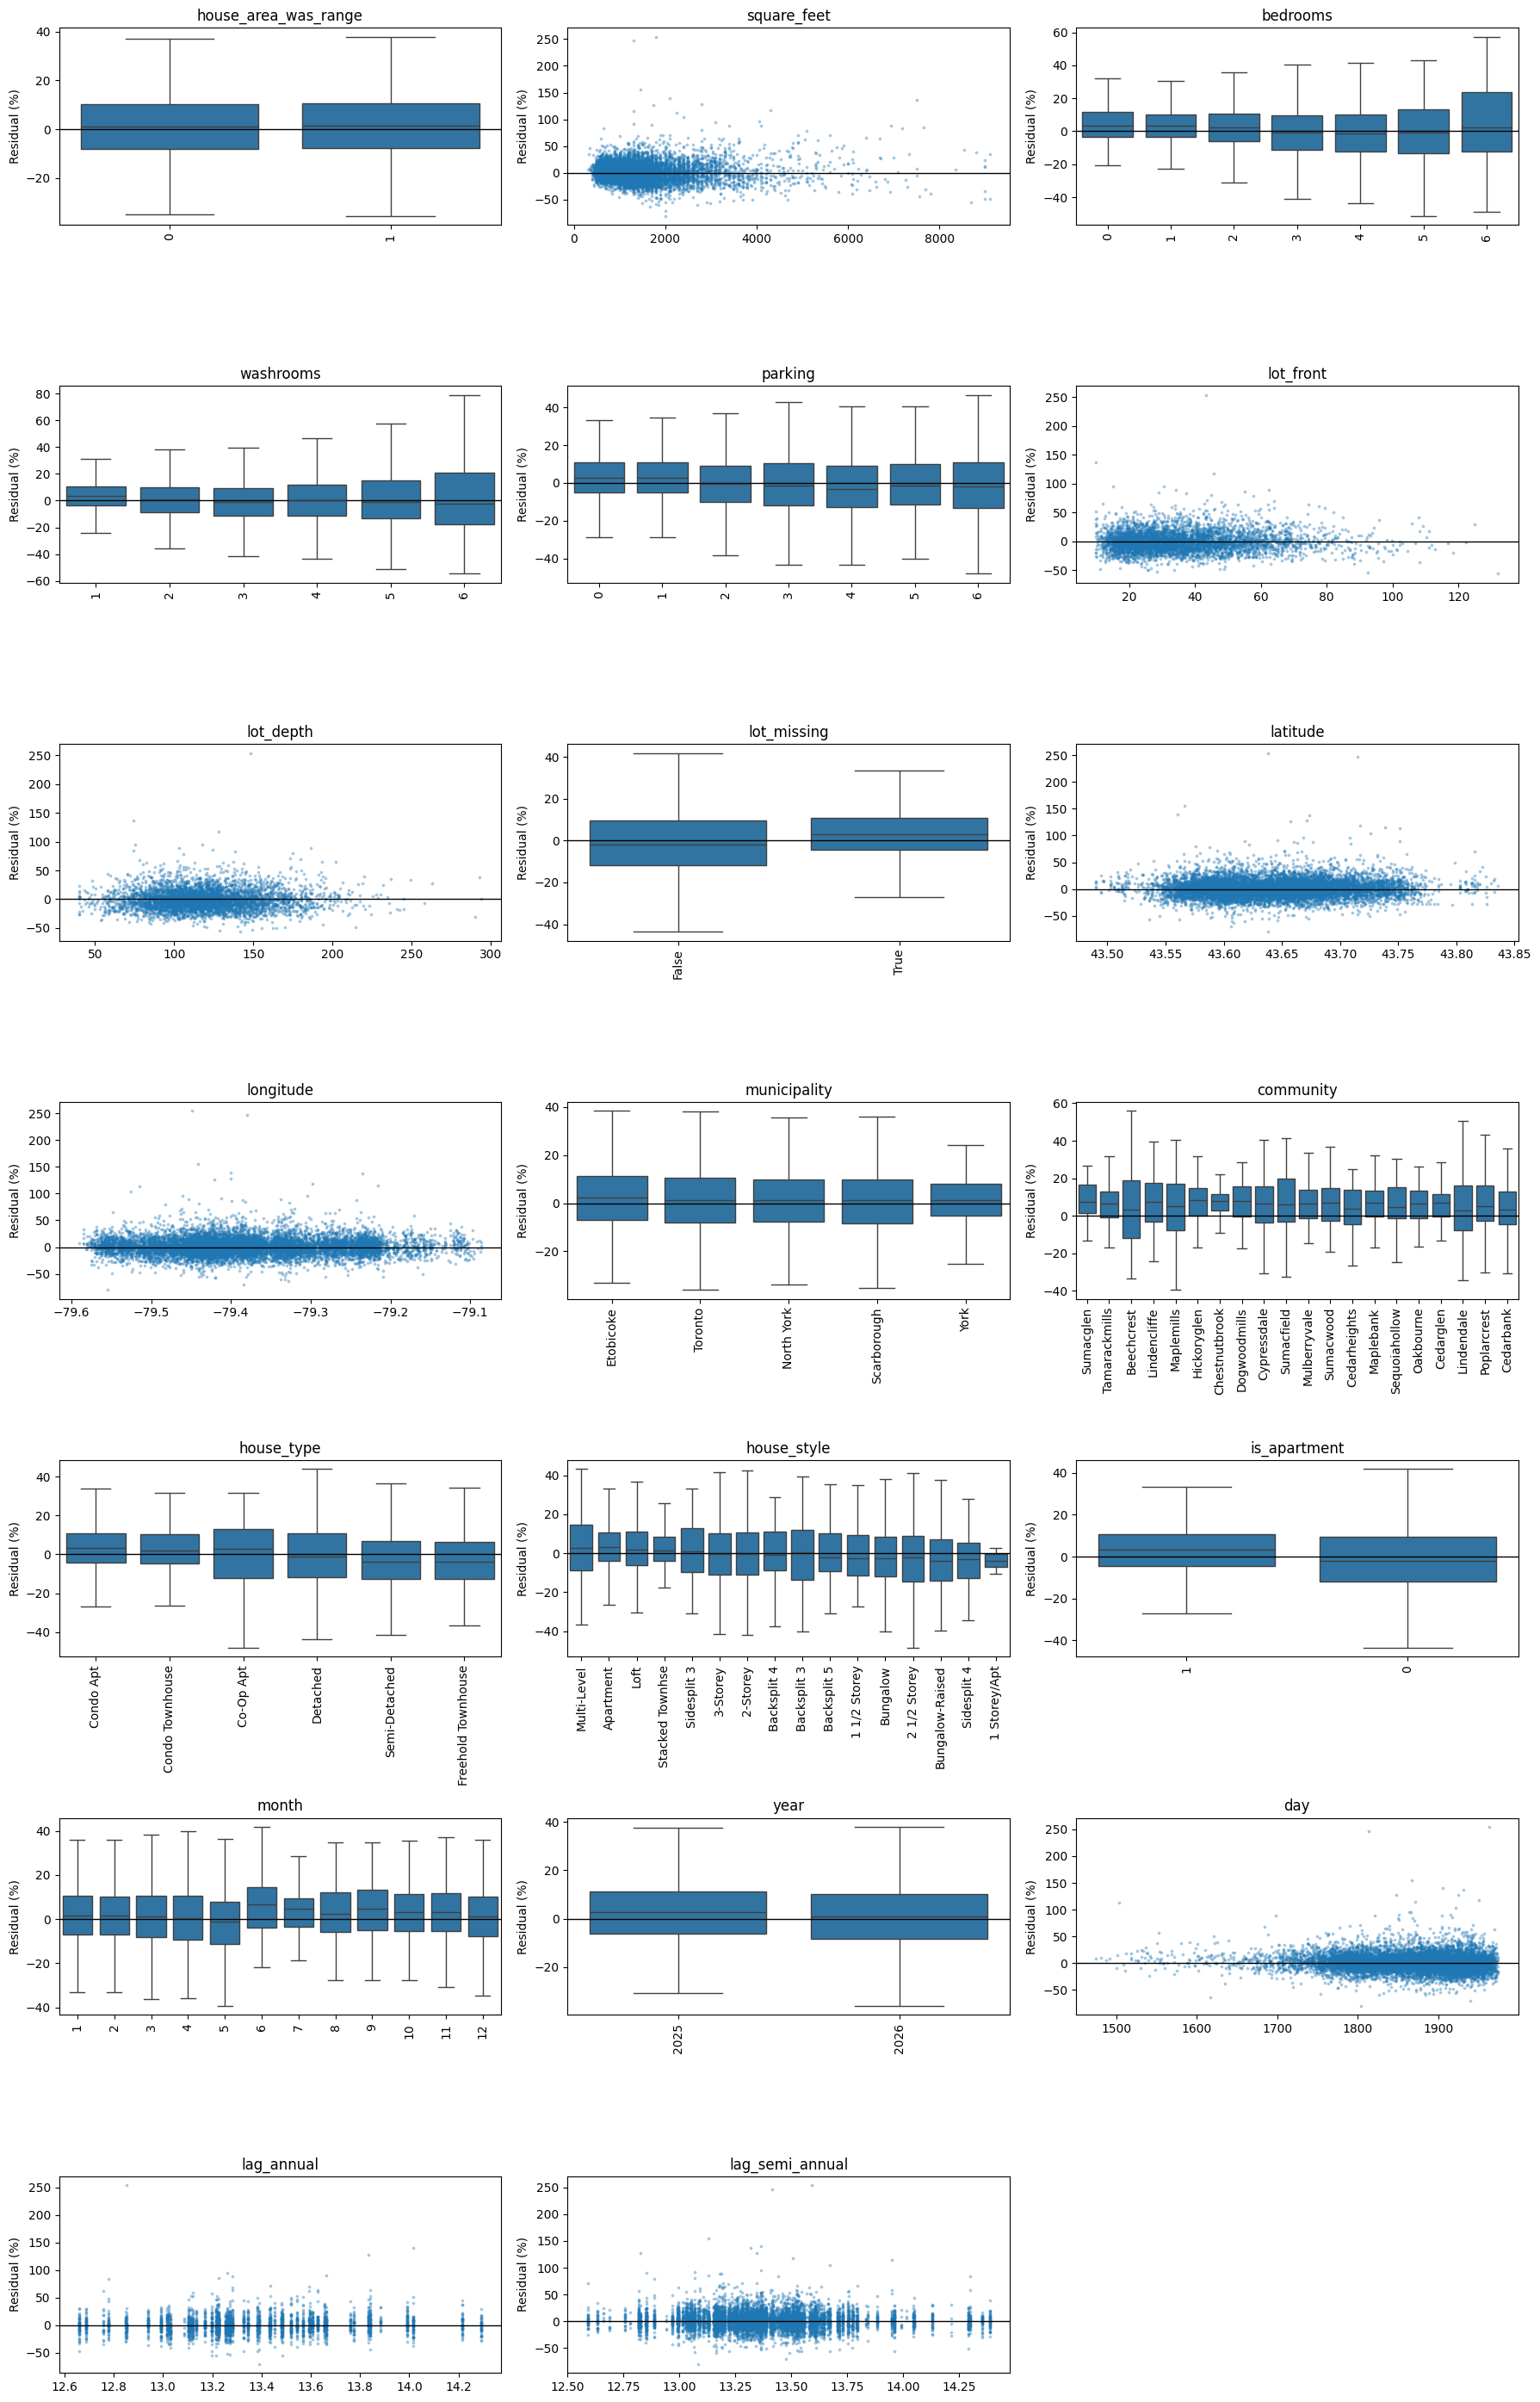

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_residuals_by_feature(X, actual, predicted, max_categories=20, n_cols=3):
    """One panel per column of X: a scatter plot for continuous columns and a box plot
    for categorical ones. Numeric columns with at most max_categories distinct values
    (bedrooms, month, ...) count as categorical. Columns with more categories than that
    show only their max_categories most common values."""
    residual = percent_error(actual, predicted)
    n_rows = int(np.ceil(len(X.columns) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows), squeeze=False)

    for ax, column in zip(axes.flat, X.columns):
        values = X[column].to_numpy()
        is_numeric = pd.api.types.is_numeric_dtype(X[column])
        if is_numeric and X[column].nunique() > max_categories:
            ax.scatter(values, residual, s=3, alpha=0.3)
        else:
            if is_numeric:
                order = sorted(X[column].value_counts().index[:max_categories])
            else:
                order = (
                    pd.DataFrame({"category": X[column], "residual": residual})
                    .groupby("category")["residual"]
                    .mean()
                    .sort_values(ascending=False)
                    .head(max_categories)
                    .index
                    .tolist()
                )
            sns.boxplot(x=values, y=residual, order=order, showfliers=False, ax=ax)
            ax.tick_params(axis="x", rotation=90)
        ax.axhline(0, color="black", linewidth=1)
        ax.set(title=column, xlabel="", ylabel="Residual (%)")

    for ax in axes.flat[len(X.columns):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()

def percent_error(actual, predicted):
    return 100 * (np.asarray(predicted) / np.asarray(actual) - 1)

plot_residuals_by_feature(X_val, actual, predicted)

In [16]:
def evaluate_by_quantile(y_true, y_pred, n_bins=10):
    df = pd.DataFrame({
        "actual": y_true,
        "predicted": y_pred
    })
    df["quantile"] = pd.qcut(
        df["actual"], q=n_bins, duplicates="drop"
    )
    df["residual"] = df["actual"] - df["predicted"]
    df["residual_percent"] = 100 * np.abs(df["residual"]) / df["actual"]
    return df.groupby("quantile", observed=True).agg(
        count=("actual", "size"),
        MAE=("residual", lambda x: x.abs().mean()),
        mean_residual=("residual", "mean"),
        mean_residual_percent=("residual_percent", "mean"),
        mdape=("residual_percent", lambda x: np.median(np.abs(x))),
        mape=("residual_percent", lambda x: np.mean(np.abs(x)))
    )

evaluate_by_quantile(actual, predicted, n_bins=10)

,count,MAE,mean_residual,mean_residual_percent,mdape,mape
quantile,,,,,,
"(226199.999, 440480.0]",1007,48574.869215,-44456.054823,13.220219,10.549833,13.220219
"(440480.0, 521000.0]",1008,42718.871039,-30432.994510,8.889941,6.911372,8.889941
"(521000.0, 597040.0]",1006,53182.918619,-27805.157239,9.519171,6.684871,9.519171
"(597040.0, 692020.0]",1007,62573.367045,-25550.063832,9.702441,7.368112,9.702441
"(692020.0, 805300.0]",1009,78039.078204,-29764.843786,10.421856,8.431856,10.421856
"(805300.0, 939280.0]",1004,92958.259767,-23782.604153,10.688346,7.898951,10.688346
"(939280.0, 1101060.0]",1007,109328.419166,2633.014884,10.715456,9.153339,10.715456
"(1101060.0, 1316500.0]",1007,147964.789868,38303.672870,12.308906,10.406754,12.308906
"(1316500.0, 1761240.0]",1007,220453.253133,65386.805767,14.657073,12.683499,14.657073
